# 05 — EDA on the full series, version 2 (window 4 Mar – 30 Sep 2021)

**Changes from version 1** (decisions of 3 Oct 2026, provisional until the supervisor meeting):
1. Window starts on **2021-03-04** (February is a ramp-up regime with incomplete telemetry; the 2 Mar maintenance window ends on 3 Mar).
2. **Relative ramp** definition added: |P(t+h) − P(t)| / L(t), with L(t) the causal mean of valid power over the past 24 h; absolute kW thresholds kept for comparison (cell 12).
3. Five-minute dip: target unchanged; h = 1 persistence also reported without mod-0 target minutes (cell 10).
4. util/temp means filled with 0 on minutes with no GPU stream (cluster up), flag `no_gpu` (cell 6).
5. Time axis: `minute_local` is the **New York wall clock** (the non-existent DST hour 2021-03-14 02:00–02:59 is empty in the telemetry while jobs run in the log); these 60 minutes are flagged `dst_gap` and excluded. The log is on the same clock (log/telemetry changes align at lag 0–1 min).
6. Fixes: W per GPU = null when no GPU-equivalent; `is_in` warning.
7. H3: partial correlation and incremental R² of covariate changes beyond the past of P (cell 14).

**Outputs** (new names, version 1 files are kept): `data/processed/series_full.parquet` and `series_full_features.parquet` are **overwritten** with the new window;
figures in `reports/figures/eda_full_v2/`; summary `reports/eda_full_summary_v2.json`.

**How to run.** Kernel "Python (dcpower)". Restart the kernel, then run all cells top to bottom (cells 2 and 3 are unchanged checks). Paste the outputs of cells 4–14.

In [1]:
# Cell 1: setup (every later cell needs this cell)
import sys, json, time, subprocess
from pathlib import Path
from datetime import datetime, timedelta, date
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_float_precision(4)
pl.Config.set_tbl_hide_dataframe_shape(True)

DATA = Path("../data")
RAW_FULL = DATA / "processed/series_full_2021.parquet"    # Colab output, whole window, unclipped
JULSEP = DATA / "processed/series_julsep.parquet"          # Jul-Sep slice used in notebook 04
SERIES = DATA / "processed/series_full.parquet"            # analysis window (written by cell 4)
FEAT = DATA / "processed/series_full_features.parquet"     # log features (written by cell 5)
LOG = DATA / "raw/slurm-log.csv"
SCRIPT = Path("../src/data/build_log_features.py")
FIG = Path("../reports/figures/eda_full_v2")
FIG.mkdir(parents=True, exist_ok=True)
SUMMARY = Path("../reports/eda_full_summary_v2.json")
HORIZONS = [1, 5, 15]
R = {}   # key results; printed and saved by cell 15

for p in [RAW_FULL, JULSEP, LOG, SCRIPT]:
    info = f"OK  {p.stat().st_size / 2**20:,.1f} MiB" if p.exists() else "MISSING"
    print(f"{str(p):48s} {info}")
for p in [SERIES, FEAT]:
    print(f"{str(p):48s} {'exists (will be overwritten by cells 4/5)' if p.exists() else 'not yet (cells 4/5 write it)'}")
print("python:", sys.executable)
print(f"polars {pl.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

../data/processed/series_full_2021.parquet       OK  18.5 MiB
../data/processed/series_julsep.parquet          OK  7.3 MiB
../data/raw/slurm-log.csv                        OK  98.4 MiB
../src/data/build_log_features.py                OK  0.0 MiB
../data/processed/series_full.parquet            exists (will be overwritten by cells 4/5)
../data/processed/series_full_features.parquet   exists (will be overwritten by cells 4/5)
python: /opt/miniconda3/envs/dcpower/bin/python
polars 1.44.2 | numpy 2.4.6 | matplotlib 3.11.2


In [2]:
# Cell 2: checks of the raw full series and data coverage per month / day (needs cell 1)
s = pl.read_parquet(RAW_FULL).sort("minute_epoch")
steps = s["minute_epoch"].diff().drop_nulls().unique().to_list()
print(f"rows {s.height:,} (expected 394,560) | columns {s.width} | steps (s) {steps}")
print("first / last minute_local:", s["minute_local"].min(), "/", s["minute_local"].max())
print("null counts:")
print(s.null_count())
print(f"power_W min {s['power_W'].min():.1f} W | max {s['power_W'].max() / 1000:.2f} kW | "
      f"n_gpu_equiv max {s['n_gpu_equiv'].max():.2f} | n_gpu_streams max {s['n_gpu_streams'].max()} (cluster: 448 GPUs)")

has = pl.col("n_gpu_streams") > 0
monthly = (s.group_by(pl.col("minute_local").dt.strftime("%Y-%m").alias("month"))
            .agg(pl.len().alias("minutes"), has.sum().alias("with_stream"), has.mean().alias("share"),
                 (pl.col("power_W") / 1000).mean().alias("mean_kW"), (pl.col("power_W") / 1000).max().alias("max_kW"),
                 pl.col("n_gpu_equiv").mean().alias("mean_gpu_eq"))
            .sort("month"))
print("\nper month (all minutes):"); print(monthly)

daily = (s.group_by(pl.col("minute_local").dt.date().alias("date"))
          .agg(has.mean().alias("cov"), (pl.col("power_W") / 1000).mean().alias("mean_kW"),
               pl.col("n_gpu_streams").mean().alias("mean_streams"))
          .sort("date"))
COV_EDGE = 0.9
good = daily.filter(pl.col("cov") >= COV_EDGE)
first_day, last_day = good["date"].min(), good["date"].max()
print(f"\nfirst / last day with stream coverage >= {COV_EDGE}: {first_day} / {last_day} "
      f"({(last_day - first_day).days + 1} days)")
print("days around the start:")
print(daily.filter((pl.col("date") >= first_day - timedelta(days=7)) & (pl.col("date") <= first_day + timedelta(days=3))))
print("days around the end:")
print(daily.filter((pl.col("date") >= last_day - timedelta(days=3)) & (pl.col("date") <= last_day + timedelta(days=3))))
inner_low = daily.filter((pl.col("date") >= first_day) & (pl.col("date") <= last_day) & (pl.col("cov") < COV_EDGE))
print(f"days inside [first, last] with coverage < {COV_EDGE}: {inner_low.height}")
print(inner_low)
R["raw"] = {"rows": s.height, "first_day_cov": str(first_day), "last_day_cov": str(last_day),
            "max_kW": round(s["power_W"].max() / 1000, 3), "gpu_eq_max": round(float(s["n_gpu_equiv"].max()), 2)}

rows 394,560 (expected 394,560) | columns 12 | steps (s) [60]
first / last minute_local: 2021-01-01 00:00:00 / 2021-10-01 23:59:00
null counts:
┌──────────────┬─────────┬───────────────┬───────────────┬───────────────┬───────────────┬──────────────┬──────────────┬─────────────┬───────────────┬────────────────┬──────────────┐
│ minute_epoch ┆ power_W ┆ util_gpu_mean ┆ util_mem_mean ┆ temp_gpu_mean ┆ temp_mem_mean ┆ mem_used_sum ┆ mem_free_sum ┆ n_gpu_equiv ┆ n_gpu_streams ┆ n_edge_streams ┆ minute_local │
│ ---          ┆ ---     ┆ ---           ┆ ---           ┆ ---           ┆ ---           ┆ ---          ┆ ---          ┆ ---         ┆ ---           ┆ ---            ┆ ---          │
│ u32          ┆ u32     ┆ u32           ┆ u32           ┆ u32           ┆ u32           ┆ u32          ┆ u32          ┆ u32         ┆ u32           ┆ u32            ┆ u32          │
╞══════════════╪═════════╪═══════════════╪═══════════════╪═══════════════╪═══════════════╪══════════════╪══════════════╪════

In [3]:
# Cell 3: consistency check: Jul-Sep slice of the full series vs series_julsep.parquet (needs cells 1, 2)
# Validates build_series_lowmem.py against the original aggregation and the "slice = build with the window" assumption.
old = pl.read_parquet(JULSEP)
new = s.filter((pl.col("minute_local") >= datetime(2021, 7, 1)) & (pl.col("minute_local") < datetime(2021, 10, 1)))
print(f"rows old {old.height:,} | new {new.height:,}")
j = old.join(new, on="minute_epoch", how="full", suffix="_new", coalesce=True)
print("minutes only in one of them:", j.filter(pl.col("minute_local").is_null() | pl.col("minute_local_new").is_null()).height)
rows = []
for c in old.columns:
    if c in ("minute_epoch", "minute_local") or c + "_new" not in j.columns:
        continue
    a, b = j[c].cast(pl.Float64), j[c + "_new"].cast(pl.Float64)
    rows.append({"column": c, "max_abs_diff": (a - b).abs().max(), "null_mismatch": int((a.is_null() != b.is_null()).sum()),
                 "nan_old": int(a.is_nan().sum()), "nan_new": int(b.is_nan().sum())})
print(pl.DataFrame(rows))
R["julsep_check_max_power_diff_W"] = max(r["max_abs_diff"] or 0 for r in rows if r["column"] == "power_W")

rows old 132,480 | new 132,480
minutes only in one of them: 0
┌────────────────┬──────────────┬───────────────┬─────────┬─────────┐
│ column         ┆ max_abs_diff ┆ null_mismatch ┆ nan_old ┆ nan_new │
│ ---            ┆ ---          ┆ ---           ┆ ---     ┆ ---     │
│ str            ┆ f64          ┆ i64           ┆ i64     ┆ i64     │
╞════════════════╪══════════════╪═══════════════╪═════════╪═════════╡
│ power_W        ┆ 2.5432       ┆ 0             ┆ 0       ┆ 0       │
│ util_gpu_mean  ┆ 0.0271       ┆ 0             ┆ 0       ┆ 0       │
│ util_mem_mean  ┆ 0.0052       ┆ 0             ┆ 0       ┆ 0       │
│ temp_gpu_mean  ┆ 0.0036       ┆ 0             ┆ 0       ┆ 0       │
│ temp_mem_mean  ┆ 0.0040       ┆ 0             ┆ 0       ┆ 0       │
│ mem_used_sum   ┆ 22.6717      ┆ 0             ┆ 0       ┆ 0       │
│ mem_free_sum   ┆ 2594.5706    ┆ 0             ┆ 0       ┆ 0       │
│ n_gpu_equiv    ┆ 0.0805       ┆ 0             ┆ 0       ┆ 0       │
│ n_gpu_streams  ┆ 0.0000   

In [4]:
# Cell 4: analysis window and slice (needs cells 1, 2). Writes data/processed/series_full.parquet.
WIN_START = date(2021, 3, 4)   # decision 1: Feb = ramp-up regime with incomplete telemetry; start after the 2 Mar maintenance window
WIN_END = None     # exclusive; None = day after the last covered day; or set e.g. date(2021, 10, 1)
ws = WIN_START or first_day
we = WIN_END or (last_day + timedelta(days=1))
t0, t1 = datetime(ws.year, ws.month, ws.day), datetime(we.year, we.month, we.day)
ser = s.filter((pl.col("minute_local") >= t0) & (pl.col("minute_local") < t1))
n_days = (we - ws).days
print(f"window {ws} .. {we} (exclusive) | {n_days} days | rows {ser.height:,} (expected {n_days * 1440:,})")
print(f"minutes with no stream inside the window: {ser.filter(pl.col('n_gpu_streams') == 0).height:,} "
      f"(cell 5 splits them into outage = null and cluster-up = 0)")
ser.write_parquet(SERIES)
print(f"written {SERIES} ({SERIES.stat().st_size / 2**20:.2f} MiB)")
R["window"] = {"start": str(ws), "end_excl": str(we), "days": n_days, "rows": ser.height}

window 2021-03-04 .. 2021-10-01 (exclusive) | 211 days | rows 303,840 (expected 303,840)
minutes with no stream inside the window: 6,133 (cell 5 splits them into outage = null and cluster-up = 0)
written ../data/processed/series_full.parquet (16.56 MiB)


In [5]:
# Cell 5: log features with build_log_features.py (needs cells 1, 4). Writes data/processed/series_full_features.parquet.
cmd = [sys.executable, "-u", str(SCRIPT), "--log", str(LOG), "--series", str(SERIES), "--out", str(FEAT)]
print(" ".join(cmd))
t = time.time()
r = subprocess.run(cmd, capture_output=True, text=True)
print(r.stdout)
if r.stderr.strip():
    print("STDERR (last 3000 chars):\n", r.stderr[-3000:])
print(f"exit code {r.returncode} | {time.time() - t:.0f} s")

/opt/miniconda3/envs/dcpower/bin/python -u ../src/data/build_log_features.py --log ../data/raw/slurm-log.csv --series ../data/processed/series_full.parquet --out ../data/processed/series_full_features.parquet
log rows: 395,914; with end > start: 395,914
cluster-wide gaps: 42; long (>= 6.0 h): 9
maintenance days in the whole log: ['2021-01-21', '2021-03-02', '2021-03-18', '2021-04-15', '2021-05-20', '2021-06-17', '2021-07-15', '2021-08-10', '2021-09-16']
minutes: 303,840; outage: 5,548; cluster up, no GPU job (set to 0): 585; maint_day: 10,080
null power_W after rules: 5,548; cluster-gap minutes with GPU telemetry (kept, not outage): 13
gpus_alloc max: 429 (cluster has 448 GPUs)
written: ../data/processed/series_full_features.parquet (303,840 rows, 20 columns)

exit code 0 | 1 s


In [6]:
# Cell 6: load features, validity rules, maintenance event window, split, pair helper (needs cell 1; most later cells need it)
g = (pl.read_parquet(FEAT).sort("minute_epoch")
       .with_columns(pl.col("outage").cast(pl.Boolean), pl.col("maint_day").cast(pl.Boolean),
                     pl.col("minute_local").dt.date().alias("date"), (pl.col("power_W") / 1000).alias("P")))
dser = lambda xs: list(xs)
maint = sorted(set(g.filter(pl.col("maint_day"))["date"].to_list()))
pre = [m - timedelta(days=1) for m in maint]
post = [m + timedelta(days=1) for m in maint]
hour = pl.col("minute_local").dt.hour()
# maintenance event window (session 4, provisional): last hour of the day before + maintenance day + whole day after
g = g.with_columns((pl.col("date").is_in(dser(maint)) | pl.col("date").is_in(dser(post)) |
                    (pl.col("date").is_in(dser(pre)) & (hour == 23))).alias("mwin"))
# DST spring-forward: the wall-clock hour 2021-03-14 02:00-02:59 does not exist (time axis = New York wall clock)
g = g.with_columns(((pl.col("date") == date(2021, 3, 14)) & (hour == 2)).alias("dst_gap"))
# suspicious zero: power 0 outside the window while the log says GPUs are allocated (possible telemetry gap)
g = g.with_columns(((pl.col("power_W") == 0) & ~pl.col("mwin") & ~pl.col("dst_gap") & (pl.col("gpus_alloc") > 0)).alias("susp_zero"))
EXCLUDE_SUSP_ZERO = True   # provisional choice; reported below
g = g.with_columns((~pl.col("outage") & ~pl.col("mwin") & ~pl.col("dst_gap") & pl.col("power_W").is_not_null() &
                    (~pl.col("susp_zero") if EXCLUDE_SUSP_ZERO else pl.lit(True))).alias("valid"))
n = g.height
i_tr, i_va = int(0.7 * n), int(0.85 * n)
g = (g.with_row_index("i")
      .with_columns(pl.when(pl.col("i") < i_tr).then(pl.lit("train"))
                      .when(pl.col("i") < i_va).then(pl.lit("val")).otherwise(pl.lit("test")).alias("split"),
                    ((pl.col("minute_epoch") // 60) % 5).alias("mod5"),
                    pl.when(pl.col("n_gpu_equiv") > 0).then(pl.col("power_W") / pl.col("n_gpu_equiv")).otherwise(None).alias("Wpg")))
# decision 4: util/temp means are undefined when no GPU stream exists (cluster up); fill with 0 and keep a flag
FILL = ["util_gpu_mean", "util_mem_mean", "temp_gpu_mean", "temp_mem_mean"]
g = g.with_columns((~pl.col("outage") & (pl.col("n_gpu_streams") == 0)).alias("no_gpu"))
g = g.with_columns([pl.when(pl.col("no_gpu")).then(pl.col(c).fill_null(0.0)).otherwise(pl.col(c)).alias(c) for c in FILL])
P = g["P"].to_numpy().astype(float)
VALID = g["valid"].to_numpy()
ML = g["minute_local"]

def pairs(h):
    """indices t with both t and t+h valid; split of the pair: train = both ends < i_tr,
    val = start >= i_tr and end < i_va, test = start >= i_va; returns dict split -> index array."""
    t = np.arange(n - h)
    ok = VALID[t] & VALID[t + h]
    t = t[ok]
    return {"train": t[t + h < i_tr], "val": t[(t >= i_tr) & (t + h < i_va)], "test": t[t >= i_va]}

zero = g.filter(pl.col("power_W") == 0)
print(f"rows {n:,} | {g['date'].min()} .. {g['date'].max()}")
print(f"maintenance days in window ({len(maint)}): {[str(m) for m in maint]}")
print(f"outage minutes {g['outage'].sum():,} | null power {g['power_W'].null_count():,} | "
      f"zero-power minutes {zero.height:,} (inside mwin {zero['mwin'].sum():,}, outside {(~zero['mwin']).sum():,})")
print(f"DST gap minutes (2021-03-14 02:00-02:59, excluded): {g['dst_gap'].sum()} | no_gpu minutes (util/temp filled with 0): {g['no_gpu'].sum():,} "
      f"| util/temp nulls left outside outages: {g.filter(~pl.col('outage')).select(FILL).null_count().row(0)}")
uo = (g.filter(pl.col("outage") & ~pl.col("mwin")).group_by("date")
        .agg(pl.col("minute_local").min().alias("first"), pl.col("minute_local").max().alias("last"), pl.len().alias("min")).sort("date"))
print(f"outages outside the maintenance window (unscheduled): {uo.height}"); print(uo)
print(f"suspicious zeros (outside mwin, gpus_alloc > 0): {g['susp_zero'].sum():,} | excluded: {EXCLUDE_SUSP_ZERO}")
zo = (zero.filter(~pl.col("mwin")).group_by("date")
          .agg(pl.len().alias("zero_min"), pl.col("susp_zero").sum().alias("susp"), pl.col("gpus_alloc").max().alias("max_alloc"))
          .sort("zero_min", descending=True))
print(f"days with zero minutes outside mwin: {zo.height} (top 15)"); print(zo.head(15))
print(f"mwin minutes {g['mwin'].sum():,} | valid minutes {g['valid'].sum():,} ({g['valid'].mean():.4f})")
b = g.filter(pl.col("i").is_in([0, i_tr, i_va, n - 1]))["minute_local"].to_list()
print(f"split: train {b[0]} .. < {b[1]} | val .. < {b[2]} | test .. {b[3]}")
ms = g.filter(pl.col("maint_day")).group_by("date").agg(pl.col("split").first()).sort("date")
print("maintenance day -> split:", {str(d): sp for d, sp in ms.iter_rows()})
R["validity"] = {"maint_days": [str(m) for m in maint], "outage_min": int(g["outage"].sum()),
                 "zero_min": zero.height, "susp_zero": int(g["susp_zero"].sum()), "mwin_min": int(g["mwin"].sum()),
                 "valid_min": int(g["valid"].sum()), "dst_gap": int(g["dst_gap"].sum()), "unscheduled_outage_days": [str(d) for d in uo["date"].to_list()], "split_bounds": [str(x) for x in b]}

rows 303,840 | 2021-03-04 .. 2021-09-30
maintenance days in window (7): ['2021-03-18', '2021-04-15', '2021-05-20', '2021-06-17', '2021-07-15', '2021-08-10', '2021-09-16']
outage minutes 5,548 | null power 5,548 | zero-power minutes 585 (inside mwin 475, outside 110)
DST gap minutes (2021-03-14 02:00-02:59, excluded): 60 | no_gpu minutes (util/temp filled with 0): 585 | util/temp nulls left outside outages: (0, 0, 0, 0)
outages outside the maintenance window (unscheduled): 1
┌────────────┬─────────────────────┬─────────────────────┬─────┐
│ date       ┆ first               ┆ last                ┆ min │
│ ---        ┆ ---                 ┆ ---                 ┆ --- │
│ date       ┆ datetime[μs]        ┆ datetime[μs]        ┆ u32 │
╞════════════╪═════════════════════╪═════════════════════╪═════╡
│ 2021-03-29 ┆ 2021-03-29 12:22:00 ┆ 2021-03-29 15:12:00 ┆ 163 │
└────────────┴─────────────────────┴─────────────────────┴─────┘
suspicious zeros (outside mwin, gpus_alloc > 0): 49 | excluded: Tr

per month (statistics on valid minutes):
┌─────────┬───────────┬────────────┬──────────┬─────────┬───────────┬─────────┬─────────┬─────────┬──────────┬──────────┬──────────────┬───────────┬──────────┐
│ month   ┆ valid_min ┆ outage_min ┆ zero_min ┆ mean_kW ┆ median_kW ┆ p01_kW  ┆ p99_kW  ┆ max_kW  ┆ gpu_eq   ┆ alloc    ┆ eq/alloc_med ┆ W_per_gpu ┆ util_gpu │
│ ---     ┆ ---       ┆ ---        ┆ ---      ┆ ---     ┆ ---       ┆ ---     ┆ ---     ┆ ---     ┆ ---      ┆ ---      ┆ ---          ┆ ---       ┆ ---      │
│ str     ┆ u32       ┆ u32        ┆ u32      ┆ f64     ┆ f64       ┆ f64     ┆ f64     ┆ f64     ┆ f64      ┆ f64      ┆ f64          ┆ f64       ┆ f64      │
╞═════════╪═══════════╪════════════╪══════════╪═════════╪═══════════╪═════════╪═════════╪═════════╪══════════╪══════════╪══════════════╪═══════════╪══════════╡
│ 2021-03 ┆ 37108     ┆ 993        ┆ 134      ┆ 16.7852 ┆ 16.2467   ┆ 3.2112  ┆ 25.7511 ┆ 27.5917 ┆ 179.3375 ┆ 195.4322 ┆ 0.9309       ┆ 93.7084   ┆ 50.6864  │

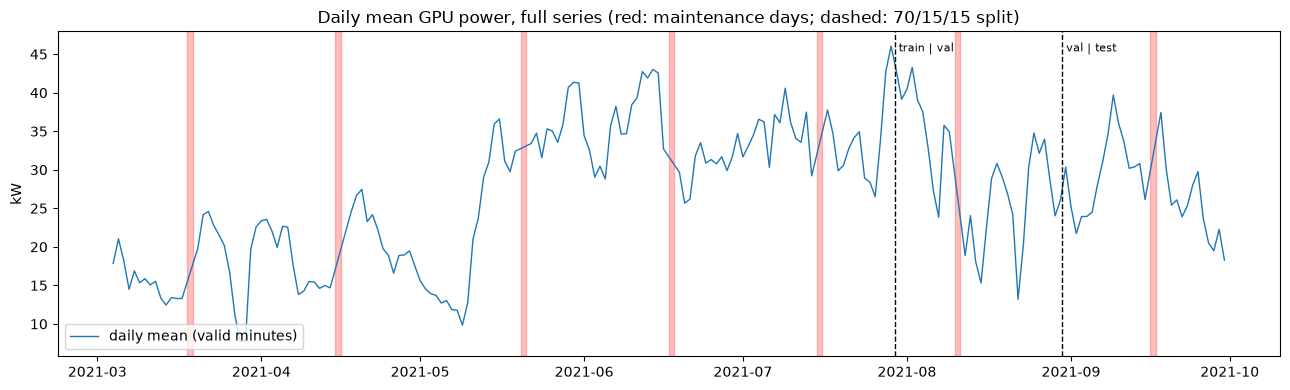

In [7]:
# Cell 7: monthly level, telemetry vs log coverage, split statistics, daily-mean figure (needs cells 1, 6)
v = g.filter(pl.col("valid"))
mon = (g.group_by(pl.col("minute_local").dt.strftime("%Y-%m").alias("month"))
        .agg(pl.col("valid").sum().alias("valid_min"), pl.col("outage").sum().alias("outage_min"),
             (pl.col("power_W") == 0).sum().alias("zero_min"))
        .join(v.group_by(pl.col("minute_local").dt.strftime("%Y-%m").alias("month"))
               .agg(pl.col("P").mean().alias("mean_kW"), pl.col("P").median().alias("median_kW"),
                    pl.col("P").quantile(0.01).alias("p01_kW"), pl.col("P").quantile(0.99).alias("p99_kW"),
                    pl.col("P").max().alias("max_kW"), pl.col("n_gpu_equiv").mean().alias("gpu_eq"),
                    pl.col("gpus_alloc").mean().alias("alloc"),
                    (pl.col("n_gpu_equiv") / pl.col("gpus_alloc")).filter(pl.col("gpus_alloc") > 0).median().alias("eq/alloc_med"),
                    pl.col("Wpg").mean().alias("W_per_gpu"), pl.col("util_gpu_mean").mean().alias("util_gpu")),
               on="month", how="left")
        .sort("month"))
print("per month (statistics on valid minutes):"); print(mon)

spl = (v.group_by("split").agg(pl.len().alias("valid_min"), pl.col("P").mean().alias("mean"), pl.col("P").std().alias("std"),
                               pl.col("P").min().alias("min"), pl.col("P").median().alias("median"), pl.col("P").max().alias("max"))
         .sort(pl.col("split").replace_strict({"train": 0, "val": 1, "test": 2})))
print("\nper split (valid minutes, kW):"); print(spl)

dm = (v.group_by("date").agg(pl.col("P").mean().alias("P"), pl.len().alias("nv")).filter(pl.col("nv") >= 1200).sort("date"))
print(f"\ndaily means (days with >= 1200 valid minutes: {dm.height}): min {dm['P'].min():.2f} on {dm.sort('P')['date'][0]}, "
      f"max {dm['P'].max():.2f} on {dm.sort('P', descending=True)['date'][0]}; "
      f"first 30 days {dm['P'].head(30).mean():.2f}, last 30 days {dm['P'].tail(30).mean():.2f} kW")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(dm["date"].to_list(), dm["P"].to_list(), lw=1, label="daily mean (valid minutes)")
for x, lab in [(b[1], "train | val"), (b[2], "val | test")]:
    ax.axvline(x, color="k", ls="--", lw=1); ax.text(x, ax.get_ylim()[1] * 0.97, " " + lab, fontsize=8, va="top")
for m in maint:
    ax.axvspan(m, m + timedelta(days=1), color="red", alpha=0.25)
ax.set_ylabel("kW"); ax.set_title("Daily mean GPU power, full series (red: maintenance days; dashed: 70/15/15 split)")
ax.legend(loc="lower left"); fig.tight_layout(); fig.savefig(FIG / "01_series_full.png", dpi=150); plt.show()
R["split_mean_kW"] = {r["split"]: round(r["mean"], 3) for r in spl.iter_rows(named=True)}
R["monthly_mean_kW"] = {r["month"]: (round(r["mean_kW"], 3) if r["mean_kW"] is not None else None) for r in mon.iter_rows(named=True)}

per ISO week (valid minutes):
┌──────────┬────────────┬───────────┬─────────┬──────────┬───────────┬──────────┬──────────┬────────────┬──────────┐
│ week     ┆ from       ┆ valid_min ┆ P_kW    ┆ gpu_eq   ┆ W_per_gpu ┆ alloc    ┆ gpu_jobs ┆ queued_gpu ┆ util_gpu │
│ ---      ┆ ---        ┆ ---       ┆ ---     ┆ ---      ┆ ---       ┆ ---      ┆ ---      ┆ ---        ┆ ---      │
│ str      ┆ date       ┆ u32       ┆ f64     ┆ f64      ┆ f64       ┆ f64      ┆ f64      ┆ f64        ┆ f64      │
╞══════════╪════════════╪═══════════╪═════════╪══════════╪═══════════╪══════════╪══════════╪════════════╪══════════╡
│ 2021-W09 ┆ 2021-03-04 ┆ 5760      ┆ 17.8996 ┆ 207.4237 ┆ 86.8121   ┆ 209.0460 ┆ 157.0069 ┆ 273.8880   ┆ 44.8654  │
│ 2021-W10 ┆ 2021-03-08 ┆ 10020     ┆ 14.9370 ┆ 155.7533 ┆ 96.5289   ┆ 167.3276 ┆ 110.7430 ┆ 28.1941    ┆ 53.4103  │
│ 2021-W11 ┆ 2021-03-15 ┆ 7140      ┆ 16.8253 ┆ 168.1880 ┆ 100.0089  ┆ 201.0867 ┆ 127.1419 ┆ 35.9783    ┆ 54.8535  │
│ 2021-W12 ┆ 2021-03-22 ┆ 10080   

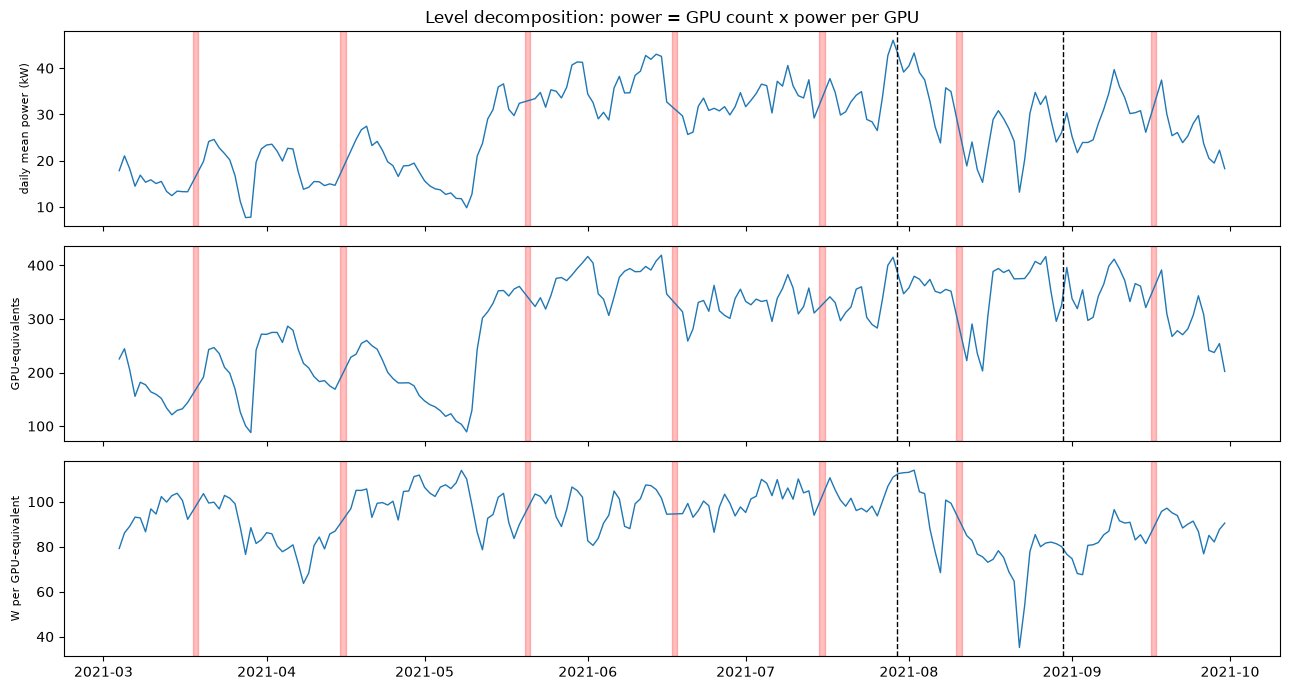

In [8]:
# Cell 8: level shifts: weekly table and decomposition P = GPU-equivalents x W per GPU (needs cells 1, 6, 7)
wk = (v.group_by(pl.col("date").dt.strftime("%G-W%V").alias("week"))
       .agg(pl.col("date").min().alias("from"), pl.len().alias("valid_min"), pl.col("P").mean().alias("P_kW"),
            pl.col("n_gpu_equiv").mean().alias("gpu_eq"), pl.col("Wpg").mean().alias("W_per_gpu"),
            pl.col("gpus_alloc").mean().alias("alloc"), pl.col("active_gpu_jobs").mean().alias("gpu_jobs"),
            pl.col("queued_gpu_jobs").mean().alias("queued_gpu"), pl.col("util_gpu_mean").mean().alias("util_gpu"))
       .sort("from"))
print("per ISO week (valid minutes):"); print(wk)

dd = (v.filter(pl.col("n_gpu_equiv") > 0)
       .group_by("date").agg(pl.col("P").mean().alias("P"), pl.col("n_gpu_equiv").mean().alias("G"), pl.len().alias("nv"))
       .filter(pl.col("nv") >= 1200).sort("date")
       .with_columns((pl.col("P") * 1000 / pl.col("G")).alias("W")))
lp, lg, lw = (np.log(dd[c].to_numpy()) for c in ["P", "G", "W"])
vp = lp.var()
print(f"\nvariance of log daily mean power: {vp:.4f}; shares: GPU count {lg.var() / vp:.3f}, W per GPU {lw.var() / vp:.3f}, "
      f"2*cov {2 * np.cov(lg, lw, bias=True)[0, 1] / vp:.3f}  (days {dd.height}; uses mean P / mean G per day)")
dP7 = dd.with_columns(pl.col("P").rolling_mean(7, center=True).alias("P7")).with_columns(pl.col("P7").diff(7).alias("chg7"))
print("largest changes of the centred 7-day mean over 7 days (kW):")
print(dP7.drop_nulls("chg7").with_columns(pl.col("chg7").abs().alias("abs")).sort("abs", descending=True)
         .head(8).select("date", "P7", "chg7").sort("date"))

fig, axs = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for ax, c, lab in zip(axs, ["P", "G", "W"], ["daily mean power (kW)", "GPU-equivalents", "W per GPU-equivalent"]):
    ax.plot(dd["date"].to_list(), dd[c].to_list(), lw=1); ax.set_ylabel(lab, fontsize=8)
    for m in maint: ax.axvspan(m, m + timedelta(days=1), color="red", alpha=0.25)
    for x in (b[1], b[2]): ax.axvline(x, color="k", ls="--", lw=1)
axs[0].set_title("Level decomposition: power = GPU count x power per GPU")
fig.tight_layout(); fig.savefig(FIG / "02_level_decomposition.png", dpi=150); plt.show()
R["level_var_share"] = {"gpu": round(lg.var() / vp, 3), "w_per_gpu": round(lw.var() / vp, 3)}

daily cycle: days with 24 full hours 188 | share of within-day variance explained by hour 0.0626
  null A (hours shuffled within day): mean 0.0053, 95th 0.0082, p 0.000
  null B (circular shift per day, keeps autocorrelation): mean 0.0054, 95th 0.0128, p 0.000
  hourly profile (kW): 0:+0.49 1:+0.42 2:+0.24 3:-0.00 4:-0.25 5:-0.56 6:-0.89 7:-0.94 8:-1.12 9:-1.18 10:-0.81 11:-0.48 12:-0.14 13:+0.13 14:+0.36 15:+0.44 16:+0.64 17:+0.74 18:+0.71 19:+0.58 20:+0.47 21:+0.35 22:+0.39 23:+0.40
  daily profile per month:
┌─────────┬───────────────────┬──────────┬──────────┐
│ month   ┆ peak_to_trough_kW ┆ min_hour ┆ max_hour │
│ ---     ┆ ---               ┆ ---      ┆ ---      │
│ str     ┆ f64               ┆ i8       ┆ i8       │
╞═════════╪═══════════════════╪══════════╪══════════╡
│ 2021-03 ┆ 0.9725            ┆ 9        ┆ 0        │
│ 2021-04 ┆ 1.0057            ┆ 8        ┆ 0        │
│ 2021-05 ┆ 2.5848            ┆ 9        ┆ 15       │
│ 2021-06 ┆ 1.5224            ┆ 6        ┆ 23      

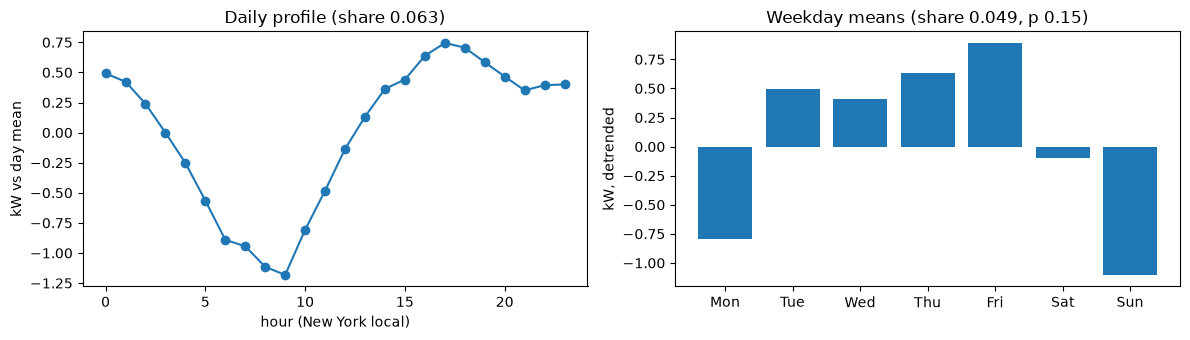

In [9]:
# Cell 9: daily and weekly profiles with two permutation nulls (needs cells 1, 6, 7)
rng = np.random.default_rng(0)
NPERM = 1000
hh = (v.group_by("date", pl.col("minute_local").dt.hour().alias("hour"))
       .agg(pl.col("P").mean().alias("P"), pl.len().alias("nv")).filter(pl.col("nv") >= 45))
full_days = hh.group_by("date").agg(pl.len().alias("nh")).filter(pl.col("nh") == 24)["date"]
hh = hh.filter(pl.col("date").is_in(full_days.to_list())).sort("date", "hour")
M = hh["P"].to_numpy().reshape(-1, 24)
D = M - M.mean(axis=1, keepdims=True)          # hourly deviation from the day mean
def share(D):
    prof = D.mean(axis=0)
    return (prof ** 2).sum() * D.shape[0] / (D ** 2).sum(), prof
obs, prof = share(D)
null_shuf = np.array([share(np.array([rng.permutation(r) for r in D]))[0] for _ in range(NPERM)])
null_rot = np.array([share(np.array([np.roll(r, rng.integers(24)) for r in D]))[0] for _ in range(NPERM)])
print(f"daily cycle: days with 24 full hours {D.shape[0]} | share of within-day variance explained by hour {obs:.4f}")
print(f"  null A (hours shuffled within day): mean {null_shuf.mean():.4f}, 95th {np.quantile(null_shuf, .95):.4f}, p {(null_shuf >= obs).mean():.3f}")
print(f"  null B (circular shift per day, keeps autocorrelation): mean {null_rot.mean():.4f}, 95th {np.quantile(null_rot, .95):.4f}, p {(null_rot >= obs).mean():.3f}")
print("  hourly profile (kW):", " ".join(f"{h}:{x:+.2f}" for h, x in enumerate(prof)))
mprof = (hh.join(hh.group_by("date").agg(pl.col("P").mean().alias("dm")), on="date")
           .with_columns((pl.col("P") - pl.col("dm")).alias("dev"), pl.col("date").dt.strftime("%Y-%m").alias("month"))
           .group_by("month", "hour").agg(pl.col("dev").mean())
           .group_by("month").agg((pl.col("dev").max() - pl.col("dev").min()).alias("peak_to_trough_kW"),
                                 pl.col("hour").sort_by("dev").first().alias("min_hour"),
                                 pl.col("hour").sort_by("dev").last().alias("max_hour")).sort("month"))
print("  daily profile per month:"); print(mprof)

dw = (v.group_by("date").agg(pl.col("P").mean().alias("P"), pl.len().alias("nv")).filter(pl.col("nv") >= 1200).sort("date")
        .upsample("date", every="1d")
        .with_columns(pl.col("P").rolling_mean(7, center=True, min_samples=5).alias("trend"))
        .with_columns((pl.col("P") - pl.col("trend")).alias("dt"), pl.col("date").dt.weekday().alias("wd"))
        .drop_nulls("dt"))
x, wdv = dw["dt"].to_numpy(), dw["wd"].to_numpy()
def wshare(x, w):
    means = np.array([x[w == k].mean() for k in range(1, 8)]); cnt = np.array([(w == k).sum() for k in range(1, 8)])
    return (cnt * (means - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum(), means
wobs, wmeans = wshare(x, wdv)
wnull = np.array([wshare(x, rng.permutation(wdv))[0] for _ in range(NPERM)])
print(f"\nweekly: detrended daily means, days {len(x)} | weekday share {wobs:.4f} | null mean {wnull.mean():.4f}, "
      f"95th {np.quantile(wnull, .95):.4f}, p {(wnull >= wobs).mean():.3f}")
print("  weekday means (kW, Mon..Sun):", " ".join(f"{m:+.2f}" for m in wmeans))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(range(24), prof, marker="o"); axs[0].set_xlabel("hour (New York local)"); axs[0].set_ylabel("kW vs day mean")
axs[0].set_title(f"Daily profile (share {obs:.3f})")
axs[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wmeans); axs[1].set_ylabel("kW, detrended")
axs[1].set_title(f"Weekday means (share {wobs:.3f}, p {(wnull >= wobs).mean():.2f})")
fig.tight_layout(); fig.savefig(FIG / "03_daily_weekly_profile.png", dpi=150); plt.show()
R["daily_share"] = round(float(obs), 4); R["daily_p_rot"] = float((null_rot >= obs).mean())
R["weekly_share"] = round(float(wobs), 4); R["weekly_p"] = float((wnull >= wobs).mean())

ACF(P): 1:0.999 5:0.997 15:0.995 60:0.985 360:0.938 720:0.894 1440:0.847 2880:0.754 10080:0.511 | first lag below 0.5: 10444
  ACF at 1440 vs min over 600..1440: 0.847 vs 0.847; at 10080 vs min over 8000..10080: 0.511 vs 0.509
ACF(dP) lags 1-6, 10, 15, 20, 30: 1:-0.247 2:-0.064 3:-0.020 4:-0.091 5:+0.099 6:-0.052 10:+0.100 15:+0.110 20:+0.094 30:+0.112 | 95% band +-0.004
PACF(P) on longest valid segment (50,340 min, 2021-08-12 00:00:00 .. 2021-09-15 22:59:00): 1:+0.998 2:+0.125 3:+0.089 4:+0.058 5:+0.068 6:+0.002 | band +-0.009

persistence P(t+h) = P(t), valid pairs (kW):
┌─────┬───────────────┬────────┬────────┬────────┬───────────┬─────────┐
│ h   ┆ split         ┆ pairs  ┆ MAE    ┆ RMSE   ┆ p95_absdP ┆ mean_P  │
│ --- ┆ ---           ┆ ---    ┆ ---    ┆ ---    ┆ ---       ┆ ---     │
│ i64 ┆ str           ┆ i64    ┆ f64    ┆ f64    ┆ f64       ┆ f64     │
╞═════╪═══════════════╪════════╪════════╪════════╪═══════════╪═════════╡
│ 1   ┆ train         ┆ 197706 ┆ 0.2650 ┆ 0.4339 ┆ 0.82

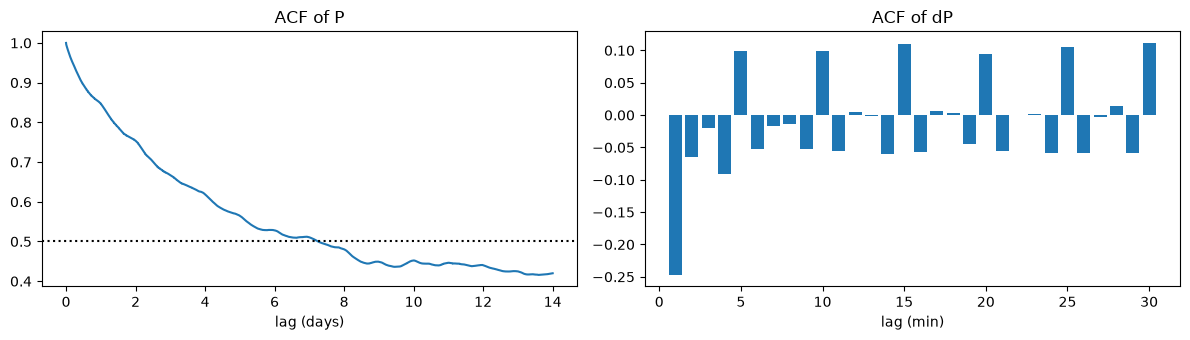

In [10]:
# Cell 10: ACF, ACF of differences, PACF, persistence baseline per split and horizon (needs cells 1, 6)
def masked_acf(x, m, maxlag):
    """ACF with missing values (global mean of valid points; sums over pairs where both are valid), via FFT."""
    x0 = np.where(m, x - x[m].mean(), 0.0); mm = m.astype(float)
    L = 1 << int(np.ceil(np.log2(2 * len(x))))
    fx, fm = np.fft.rfft(x0, L), np.fft.rfft(mm, L)
    num = np.fft.irfft(fx * np.conj(fx), L)[:maxlag + 1]
    cnt = np.round(np.fft.irfft(fm * np.conj(fm), L)[:maxlag + 1])
    c = num / np.maximum(cnt, 1)
    return c / c[0], cnt
Pm = np.where(VALID, P, np.nan)
acf, cnt = masked_acf(np.nan_to_num(Pm), VALID, 20160)
first_below = int(np.argmax(acf < 0.5)) if (acf < 0.5).any() else None
lags = [1, 5, 15, 60, 360, 720, 1440, 2880, 10080]
print("ACF(P):", " ".join(f"{k}:{acf[k]:.3f}" for k in lags), f"| first lag below 0.5: {first_below}")
print(f"  ACF at 1440 vs min over 600..1440: {acf[1440]:.3f} vs {acf[600:1441].min():.3f}; "
      f"at 10080 vs min over 8000..10080: {acf[10080]:.3f} vs {acf[8000:10081].min():.3f}")
dv = VALID[1:] & VALID[:-1]
dP = np.where(dv, np.diff(np.nan_to_num(Pm)), 0.0)
acfd, _ = masked_acf(dP, dv, 30)
print("ACF(dP) lags 1-6, 10, 15, 20, 30:", " ".join(f"{k}:{acfd[k]:+.3f}" for k in [1, 2, 3, 4, 5, 6, 10, 15, 20, 30]),
      f"| 95% band +-{1.96 / np.sqrt(dv.sum()):.3f}")

# PACF (Durbin-Levinson) on the longest valid segment
edges = np.flatnonzero(np.diff(np.r_[0, VALID.astype(int), 0]))
st, en = edges[::2], edges[1::2]; k = np.argmax(en - st)
seg = P[st[k]:en[k]]
sa, _ = masked_acf(seg, np.ones(len(seg), bool), 6)
phi = np.zeros((7, 7)); pacf = [1.0]
for kk in range(1, 7):
    phi[kk, kk] = (sa[kk] - (phi[kk - 1, 1:kk] * sa[1:kk][::-1]).sum()) / (1 - (phi[kk - 1, 1:kk] * sa[1:kk]).sum())
    phi[kk, 1:kk] = phi[kk - 1, 1:kk] - phi[kk, kk] * phi[kk - 1, 1:kk][::-1]
    pacf.append(phi[kk, kk])
print(f"PACF(P) on longest valid segment ({len(seg):,} min, {ML[int(st[k])]} .. {ML[int(en[k]) - 1]}):",
      " ".join(f"{kk}:{pacf[kk]:+.3f}" for kk in range(1, 7)), f"| band +-{1.96 / np.sqrt(len(seg)):.3f}")

rows = []
PAIRS = {h: pairs(h) for h in HORIZONS}
for h in HORIZONS:
    for sp, t in PAIRS[h].items():
        e = np.abs(P[t + h] - P[t])
        rows.append({"h": h, "split": sp, "pairs": len(t), "MAE": e.mean(), "RMSE": np.sqrt((e ** 2).mean()),
                     "p95_absdP": np.quantile(e, .95), "mean_P": P[t + h].mean()})
mod5_np = g["mod5"].to_numpy()
for sp, t in PAIRS[1].items():
    t = t[mod5_np[t + 1] != 0]; e = np.abs(P[t + 1] - P[t])
    rows.append({"h": 1, "split": sp + "_no_mod0", "pairs": len(t), "MAE": e.mean(), "RMSE": np.sqrt((e ** 2).mean()),
                 "p95_absdP": np.quantile(e, .95), "mean_P": P[t + 1].mean()})
pers = pl.DataFrame(rows)
print("\npersistence P(t+h) = P(t), valid pairs (kW):"); print(pers)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(np.arange(20161) / 1440, acf); axs[0].axhline(0.5, color="k", ls=":"); axs[0].set_xlabel("lag (days)"); axs[0].set_title("ACF of P")
axs[1].bar(range(1, 31), acfd[1:]); axs[1].set_xlabel("lag (min)"); axs[1].set_title("ACF of dP")
fig.tight_layout(); fig.savefig(FIG / "04_acf.png", dpi=150); plt.show()
R["acf_first_below_0.5"] = first_below
R["persistence_MAE"] = {f"h{r['h']}_{r['split']}": round(r["MAE"], 4) for r in rows}

In [11]:
# Cell 11: five-minute dip (H1) by month: mean change at mod 0, 1, 2-4 (needs cells 1, 6)
f = (g.with_columns(pl.col("P").diff().alias("dP"), pl.col("Wpg").diff().alias("dWpg"),
                    (pl.col("valid") & pl.col("valid").shift(1) & (pl.col("n_gpu_equiv") > 0) &
                     (pl.col("n_gpu_equiv").shift(1) > 0)).alias("ok"))
       .filter(pl.col("ok"))
       .with_columns(pl.when(pl.col("mod5") == 0).then(pl.lit("m0")).when(pl.col("mod5") == 1).then(pl.lit("m1"))
                       .otherwise(pl.lit("m234")).alias("cls"), pl.col("minute_local").dt.strftime("%Y-%m").alias("month")))
t5 = (f.group_by("month", "cls").agg(pl.col("dP").mean().alias("dP_kW"), pl.col("dWpg").mean().alias("dW_per_gpu"), pl.len().alias("n"))
       .pivot(on="cls", index="month", values=["dP_kW", "dW_per_gpu"]).sort("month"))
print(f"consecutive valid minutes: {f.height:,}"); print(t5)
tall = f.group_by("cls").agg(pl.col("dP").mean().alias("dP_kW"), pl.col("dWpg").mean().alias("dW_per_gpu"),
                             pl.col("dP").abs().mean().alias("mean_abs_dP"), pl.len().alias("n")).sort("cls")
print("whole series:"); print(tall)
R["dip_m0_dP_kW_by_month"] = {r["month"]: round(r["dP_kW_m0"], 4) for r in t5.iter_rows(named=True) if r["dP_kW_m0"] is not None}

consecutive valid minutes: 282,976
┌─────────┬────────────┬──────────┬──────────┬─────────────────┬───────────────┬───────────────┐
│ month   ┆ dP_kW_m234 ┆ dP_kW_m1 ┆ dP_kW_m0 ┆ dW_per_gpu_m234 ┆ dW_per_gpu_m1 ┆ dW_per_gpu_m0 │
│ ---     ┆ ---        ┆ ---      ┆ ---      ┆ ---             ┆ ---           ┆ ---           │
│ str     ┆ f64        ┆ f64      ┆ f64      ┆ f64             ┆ f64           ┆ f64           │
╞═════════╪════════════╪══════════╪══════════╪═════════════════╪═══════════════╪═══════════════╡
│ 2021-03 ┆ 0.0011     ┆ 0.0166   ┆ -0.0205  ┆ 0.0057          ┆ 0.1206        ┆ -0.1259       │
│ 2021-04 ┆ 0.0006     ┆ 0.0175   ┆ -0.0212  ┆ 0.0067          ┆ 0.0948        ┆ -0.1145       │
│ 2021-05 ┆ 0.0044     ┆ 0.0700   ┆ -0.0799  ┆ 0.0114          ┆ 0.2986        ┆ -0.3359       │
│ 2021-06 ┆ 0.0002     ┆ 0.1854   ┆ -0.1871  ┆ 0.0016          ┆ 0.5382        ┆ -0.5440       │
│ 2021-07 ┆ 0.0003     ┆ 0.3643   ┆ -0.3661  ┆ 0.0018          ┆ 1.0778        ┆ -1.0832    

ramp thresholds |P(t+h) - P(t)| (kW), train valid pairs; rates with train thresholds (expected 0.05 / 0.01):
┌─────┬─────────┬────────┬────────────┬────────┬────────┬────────┬─────────┬─────────┬──────────┬────────────┬────────────┬─────────────┬─────────────┐
│ h   ┆ n_train ┆ std    ┆ median_abs ┆ p90    ┆ p95    ┆ p99    ┆ max     ┆ exkurt  ┆ share_up ┆ rate95_val ┆ rate99_val ┆ rate95_test ┆ rate99_test │
│ --- ┆ ---     ┆ ---    ┆ ---        ┆ ---    ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---      ┆ ---        ┆ ---        ┆ ---         ┆ ---         │
│ i64 ┆ i64     ┆ f64    ┆ f64        ┆ f64    ┆ f64    ┆ f64    ┆ f64     ┆ f64     ┆ f64      ┆ f64        ┆ f64        ┆ f64         ┆ f64         │
╞═════╪═════════╪════════╪════════════╪════════╪════════╪════════╪═════════╪═════════╪══════════╪════════════╪════════════╪═════════════╪═════════════╡
│ 1   ┆ 197706  ┆ 0.4339 ┆ 0.1644     ┆ 0.6026 ┆ 0.8212 ┆ 1.4991 ┆ 10.8339 ┆ 41.0122 ┆ 0.4919   ┆ 0.0710     ┆ 0.0170     ┆ 0.0358 

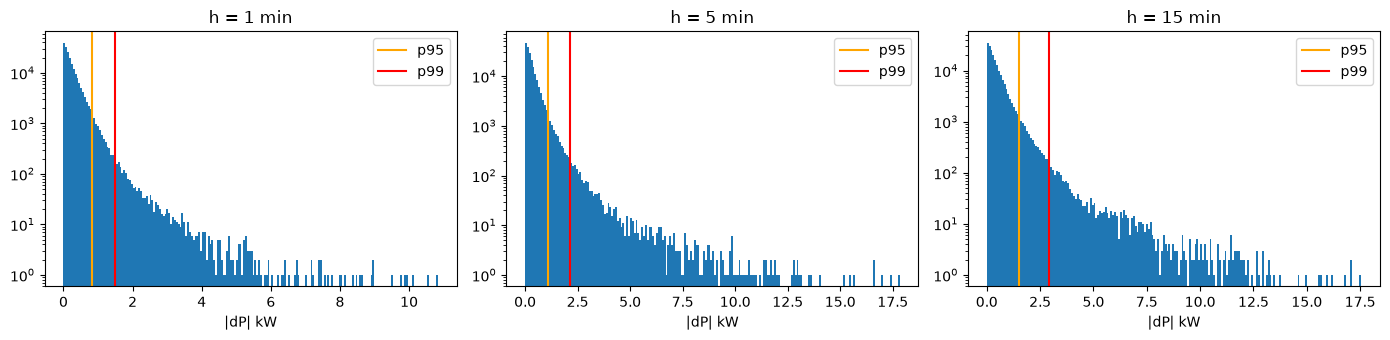

In [12]:
# Cell 12: ramp thresholds (H2) on train pairs, ramp rates in val/test and per month (needs cells 1, 6, 10)
def exkurt(x):
    z = (x - x.mean()) / x.std(); return (z ** 4).mean() - 3
rows, THR = [], {}
for h in HORIZONS:
    tr = PAIRS[h]["train"]; d = P[tr + h] - P[tr]; a = np.abs(d)
    p95, p99 = np.quantile(a, .95), np.quantile(a, .99); THR[h] = (p95, p99)
    row = {"h": h, "n_train": len(tr), "std": d.std(), "median_abs": np.median(a), "p90": np.quantile(a, .9),
           "p95": p95, "p99": p99, "max": a.max(), "exkurt": exkurt(d), "share_up": (d[a > p95] > 0).mean()}
    for sp in ["val", "test"]:
        t = PAIRS[h][sp]; aa = np.abs(P[t + h] - P[t])
        row[f"rate95_{sp}"] = (aa > p95).mean(); row[f"rate99_{sp}"] = (aa > p99).mean()
    rows.append(row)
print("ramp thresholds |P(t+h) - P(t)| (kW), train valid pairs; rates with train thresholds (expected 0.05 / 0.01):")
print(pl.DataFrame(rows))
tr = PAIRS[1]["train"]; mod5 = g["mod5"].to_numpy()
keep = (mod5[tr] != 0) & (mod5[tr + 1] != 0)
a1 = np.abs(P[tr[keep] + 1] - P[tr[keep]])
print(f"h=1 without pairs touching a mod-0 minute (n {keep.sum():,}): p95 {np.quantile(a1, .95):.3f}, p99 {np.quantile(a1, .99):.3f}")

month = g["minute_local"].dt.strftime("%Y-%m").to_numpy()
mrows = []
for h in HORIZONS:
    t = np.arange(n - h); t = t[VALID[t] & VALID[t + h]]; aa = np.abs(P[t + h] - P[t])
    for mo in np.unique(month[t]):
        sel = month[t] == mo
        mrows.append({"h": h, "month": mo, "pairs": int(sel.sum()), "rate95": (aa[sel] > THR[h][0]).mean(),
                      "rate99": (aa[sel] > THR[h][1]).mean()})
print("ramp rate per month with the train thresholds (all splits):")
print(pl.DataFrame(mrows).pivot(on="h", index="month", values=["rate95", "rate99"]).sort("month"))

# ---- relative ramp: |P(t+h) - P(t)| / L(t), L(t) = causal mean of valid P over the past 24 h (>= 720 valid minutes) ----
W24 = 1440
pv = np.where(VALID, P, 0.0); cv = VALID.astype(float)
cs, cc = np.r_[0, np.cumsum(pv)], np.r_[0, np.cumsum(cv)]
idx = np.arange(n); lo = np.maximum(idx + 1 - W24, 0)
cnt24 = cc[idx + 1] - cc[lo]
L24 = np.where(cnt24 >= 720, (cs[idx + 1] - cs[lo]) / np.maximum(cnt24, 1), np.nan)
rrows, RTHR = [], {}
for h in HORIZONS:
    tr = PAIRS[h]["train"]; tr = tr[np.isfinite(L24[tr])]; a = np.abs(P[tr + h] - P[tr]) / L24[tr]
    q95, q99 = np.quantile(a, .95), np.quantile(a, .99); RTHR[h] = (q95, q99)
    row = {"h": h, "n_train": len(tr), "p95_rel": q95, "p99_rel": q99, "p95_kW_at_30kW": q95 * 30, "p99_kW_at_30kW": q99 * 30}
    for sp in ["val", "test"]:
        t = PAIRS[h][sp]; t = t[np.isfinite(L24[t])]; aa = np.abs(P[t + h] - P[t]) / L24[t]
        row[f"rate95_{sp}"] = (aa > q95).mean(); row[f"rate99_{sp}"] = (aa > q99).mean()
    rrows.append(row)
print("\nRELATIVE ramp thresholds |dP| / L24 (train); rates with train thresholds:"); print(pl.DataFrame(rrows))
rm = []
for h in HORIZONS:
    t = np.arange(n - h); t = t[VALID[t] & VALID[t + h] & np.isfinite(L24[t])]
    aa = np.abs(P[t + h] - P[t]); rr = aa / L24[t]
    for mo in np.unique(month[t]):
        sel = month[t] == mo
        rm.append({"h": h, "month": mo, "abs95": (aa[sel] > THR[h][0]).mean(), "rel95": (rr[sel] > RTHR[h][0]).mean(),
                   "abs99": (aa[sel] > THR[h][1]).mean(), "rel99": (rr[sel] > RTHR[h][1]).mean()})
rm = pl.DataFrame(rm)
print("monthly ramp rate, absolute vs relative definition (expected 0.05 / 0.01):")
print(rm.pivot(on="h", index="month", values=["abs95", "rel95"]).sort("month"))
stab = rm.group_by("h").agg(*[(pl.col(k).std() / pl.col(k).mean()).alias(f"cv_{k}") for k in ["abs95", "rel95", "abs99", "rel99"]],
                            *[(pl.col(k).max() / pl.col(k).min()).alias(f"maxmin_{k}") for k in ["abs95", "rel95"]]).sort("h")
print("stability across months (coefficient of variation and max/min of the monthly rate; lower = more stable):"); print(stab)
R["ramp_rel_thr"] = {f"h{h}": {"p95": round(RTHR[h][0], 4), "p99": round(RTHR[h][1], 4)} for h in HORIZONS}
R["ramp_cv_monthly"] = {f"h{r['h']}": {"abs95": round(r["cv_abs95"], 3), "rel95": round(r["cv_rel95"], 3)} for r in stab.iter_rows(named=True)}

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, h in zip(axs, HORIZONS):
    a = np.abs(P[PAIRS[h]["train"] + h] - P[PAIRS[h]["train"]])
    ax.hist(a, bins=200, log=True); ax.axvline(THR[h][0], color="orange", label="p95"); ax.axvline(THR[h][1], color="red", label="p99")
    ax.set_title(f"h = {h} min"); ax.set_xlabel("|dP| kW"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "05_ramp_thresholds.png", dpi=150); plt.show()
R["ramp_thr_kW"] = {f"h{h}": {"p95": round(THR[h][0], 3), "p99": round(THR[h][1], 3)} for h in HORIZONS}

In [13]:
# Cell 13: largest one-minute jumps in train, with context (needs cells 1, 6, 10)
tr = PAIRS[1]["train"]; d = P[tr + 1] - P[tr]; a = np.abs(d)
print(f"train h=1 pairs: |dP| > 3 kW: {(a > 3).sum()} | > 5 kW: {(a > 5).sum()} | > 10 kW: {(a > 10).sum()}")
top = tr[np.argsort(-a)[:15]]
alloc, geq, wpg = g["gpus_alloc"].to_numpy(), g["n_gpu_equiv"].to_numpy(), g["Wpg"].to_numpy()
dates = g["date"].to_list()
def since_maint(dte):
    past = [m for m in maint if m <= dte]; return (dte - past[-1]).days if past else None
rows = [{"time": ML[int(t) + 1], "P0": P[t], "P1": P[t + 1], "dP": P[t + 1] - P[t], "alloc0": alloc[t], "alloc1": alloc[t + 1],
         "geq0": geq[t], "geq1": geq[t + 1], "Wpg0": wpg[t], "Wpg1": wpg[t + 1], "mod5": int(mod5[t + 1]),
         "days_since_maint": since_maint(dates[t])} for t in sorted(top)]
print(pl.DataFrame(rows))

train h=1 pairs: |dP| > 3 kW: 324 | > 5 kW: 80 | > 10 kW: 3
┌─────────────────────┬─────────┬─────────┬──────────┬────────┬────────┬──────────┬──────────┬──────────┬──────────┬──────┬──────────────────┐
│ time                ┆ P0      ┆ P1      ┆ dP       ┆ alloc0 ┆ alloc1 ┆ geq0     ┆ geq1     ┆ Wpg0     ┆ Wpg1     ┆ mod5 ┆ days_since_maint │
│ ---                 ┆ ---     ┆ ---     ┆ ---      ┆ ---    ┆ ---    ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---  ┆ ---              │
│ datetime[μs]        ┆ f64     ┆ f64     ┆ f64      ┆ i64    ┆ i64    ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ i64  ┆ i64              │
╞═════════════════════╪═════════╪═════════╪══════════╪════════╪════════╪══════════╪══════════╪══════════╪══════════╪══════╪══════════════════╡
│ 2021-05-18 18:51:00 ┆ 35.6098 ┆ 25.6532 ┆ -9.9566  ┆ 382    ┆ 382    ┆ 382.0000 ┆ 382.0000 ┆ 93.2195  ┆ 67.1550  ┆ 1    ┆ 33               │
│ 2021-05-18 19:06:00 ┆ 26.3900 ┆ 35.9070 ┆ 9.5170   ┆ 381    ┆ 381    ┆ 381.2358 

In [14]:
# Cell 14: covariates (H3): nulls, level correlation, predictive value for future dP, log vs telemetry lead/lag (needs cells 1, 6, 10)
COV = ["util_gpu_mean", "util_mem_mean", "temp_gpu_mean", "temp_mem_mean", "mem_used_sum", "mem_free_sum",
       "n_gpu_equiv", "gpus_alloc", "active_gpu_jobs", "active_jobs", "queued_gpu_jobs", "queued_jobs"]
zero_m = g["power_W"].to_numpy() == 0
nrows = [{"cov": c, "null_valid": int(g.filter(pl.col("valid"))[c].null_count()),
          "null_on_zero_power": int(g.filter(pl.col("power_W") == 0)[c].null_count()), "zero_power_min": int(zero_m.sum())} for c in COV]
print("nulls:"); print(pl.DataFrame(nrows))

X = {c: g[c].cast(pl.Float64).to_numpy() for c in COV}
def corr(a, b):
    ok = np.isfinite(a) & np.isfinite(b); return np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() > 10 else np.nan
trm = np.flatnonzero(VALID & (np.arange(n) < i_tr))
L = 5
rows = []
for c in COV + ["P"]:
    x = P if c == "P" else X[c]
    r = {"cov": c, "corr_level_P": corr(x[trm], P[trm])}
    for h in HORIZONS:
        t = PAIRS[h]["train"]; t = t[(t >= L) & VALID[t - L]]
        r[f"corr_d{L}_vs_futdP_h{h}"] = corr(x[t] - x[t - L], P[t + h] - P[t])
    rows.append(r)
print(f"\ntrain, valid: level correlation with P, and correlation of the past {L}-min change of the covariate with the future "
      f"change P(t+h) - P(t) (row 'P' = past change of P itself, the persistence-residual benchmark):")
print(pl.DataFrame(rows))

# ---- partial correlation and incremental R2 beyond the past of P (train) ----
def ols_resid(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None); return y - X @ beta
def r2(X, y):
    r = ols_resid(X, y); return 1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum()
mod5_np = g["mod5"].to_numpy()
prows = []
for h in HORIZONS:
    t = PAIRS[h]["train"]; t = t[(t >= L) & VALID[t - L] & VALID[t - 1]]
    y = P[t + h] - P[t]
    D = [np.ones(len(t)), P[t] - P[t - 1], P[t] - P[t - L], P[t]]
    D += [(mod5_np[t] == k).astype(float) for k in range(1, 5)] + [(mod5_np[(t + h)] == k).astype(float) for k in range(1, 5)]
    B = np.column_stack(D); r2b = r2(B, y); ry = ols_resid(B, y)
    row = {"h": h, "n": len(t), "R2_base": r2b}
    allc = []
    for c in COV:
        x = X[c][t] - X[c][t - L]
        if not np.isfinite(x).all(): row[c] = np.nan; continue
        allc.append(x); row[c] = np.corrcoef(ols_resid(B, x), ry)[0, 1]
    row["dR2_all"] = r2(np.column_stack([B] + allc), y) - r2b
    prows.append(row)
print(f"\npartial correlation of each covariate's past {L}-min change with the future change, after removing the past of P "
      f"(dP over 1 and {L} min, level P, mod-5 of t and t+h); dR2_all = extra R2 from all covariate changes together:")
print(pl.DataFrame(prows))
R["h3_dR2_all"] = {f"h{r['h']}": round(r["dR2_all"], 4) for r in prows}
R["h3_R2_base"] = {f"h{r['h']}": round(r["R2_base"], 4) for r in prows}

ok = VALID[1:] & VALID[:-1]
da, dg = np.diff(X["gpus_alloc"]), np.diff(X["n_gpu_equiv"])
cc = []
for lag in range(-5, 6):    # lag > 0: log change at t, telemetry change at t + lag
    if lag >= 0: a_, b_, m_ = da[:len(da) - lag], dg[lag:], ok[:len(ok) - lag] & ok[lag:]
    else: a_, b_, m_ = da[-lag:], dg[:len(dg) + lag], ok[-lag:] & ok[:len(ok) + lag]
    cc.append({"lag_min": lag, "corr(d_alloc_t, d_gpu_eq_t+lag)": corr(np.where(m_, a_, np.nan), np.where(m_, b_, np.nan))})
print("\nlead/lag of log (gpus_alloc) vs telemetry (n_gpu_equiv), 1-min changes, valid minutes:"); print(pl.DataFrame(cc))
print(f"median n_gpu_equiv / gpus_alloc (valid, alloc > 0): "
      f"{np.nanmedian(np.where(VALID & (X['gpus_alloc'] > 0), X['n_gpu_equiv'] / np.where(X['gpus_alloc'] > 0, X['gpus_alloc'], 1), np.nan)):.4f}")

nulls:
┌─────────────────┬────────────┬────────────────────┬────────────────┐
│ cov             ┆ null_valid ┆ null_on_zero_power ┆ zero_power_min │
│ ---             ┆ ---        ┆ ---                ┆ ---            │
│ str             ┆ i64        ┆ i64                ┆ i64            │
╞═════════════════╪════════════╪════════════════════╪════════════════╡
│ util_gpu_mean   ┆ 0          ┆ 0                  ┆ 585            │
│ util_mem_mean   ┆ 0          ┆ 0                  ┆ 585            │
│ temp_gpu_mean   ┆ 0          ┆ 0                  ┆ 585            │
│ temp_mem_mean   ┆ 0          ┆ 0                  ┆ 585            │
│ mem_used_sum    ┆ 0          ┆ 0                  ┆ 585            │
│ mem_free_sum    ┆ 0          ┆ 0                  ┆ 585            │
│ n_gpu_equiv     ┆ 0          ┆ 0                  ┆ 585            │
│ gpus_alloc      ┆ 0          ┆ 0                  ┆ 585            │
│ active_gpu_jobs ┆ 0          ┆ 0                  ┆ 585            │

In [15]:
# Cell 15: summary of key numbers; saves reports/eda_full_summary.json (needs cell 1 and whichever cells ran)
def clean(o):
    if isinstance(o, dict): return {k: clean(x) for k, x in o.items()}
    if isinstance(o, (list, tuple)): return [clean(x) for x in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
print(json.dumps(clean(R), indent=1, default=str))
SUMMARY.write_text(json.dumps(clean(R), indent=1, default=str))
print(f"\nsaved {SUMMARY} | figures: {sorted(p.name for p in FIG.glob('*.png'))}")

{
 "raw": {
  "rows": 394560,
  "first_day_cov": "2021-02-09",
  "last_day_cov": "2021-09-30",
  "max_kW": 64.532,
  "gpu_eq_max": 429.0
 },
 "julsep_check_max_power_diff_W": 2.543207426373556,
 "window": {
  "start": "2021-03-04",
  "end_excl": "2021-10-01",
  "days": 211,
  "rows": 303840
 },
 "validity": {
  "maint_days": [
   "2021-03-18",
   "2021-04-15",
   "2021-05-20",
   "2021-06-17",
   "2021-07-15",
   "2021-08-10",
   "2021-09-16"
  ],
  "outage_min": 5548,
  "zero_min": 585,
  "susp_zero": 49,
  "mwin_min": 20580,
  "valid_min": 282988,
  "dst_gap": 60,
  "unscheduled_outage_days": [
   "2021-03-29"
  ],
  "split_bounds": [
   "2021-03-04 00:00:00",
   "2021-07-29 16:48:00",
   "2021-08-30 08:24:00",
   "2021-09-30 23:59:00"
  ]
 },
 "split_mean_kW": {
  "train": 26.276,
  "val": 29.505,
  "test": 27.607
 },
 "monthly_mean_kW": {
  "2021-03": 16.785,
  "2021-04": 19.855,
  "2021-05": 26.306,
  "2021-06": 33.826,
  "2021-07": 34.833,
  "2021-08": 28.518,
  "2021-09": 27.509

In [17]:
   %run ../src/tools/nb_outputs_to_md.py 05_eda_full_v2.ipynb

written 05_eda_full_v2_outputs.md | code cells 17 | figures 5 in 05_eda_full_v2_outputs_figures
